Dataset: [https://www.kaggle.com/datasets/ealaxi/paysim1](https://www.kaggle.com/datasets/ealaxi/paysim1)

In [68]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#20B2AA"])

In [69]:
PAYSIM_DATA = Path("../data/raw/paysim_data.csv")

df = pd.read_csv(PAYSIM_DATA)

In [70]:
df.shape

(6362620, 11)

In [71]:
df.head(500)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
495,1,CASH_IN,160347.32,C1972143064,7965270.68,8125617.99,C33524623,724867.22,1517262.16,0,0
496,1,CASH_IN,289272.75,C312168418,8125617.99,8414890.75,C75457651,413976.60,31469.78,0,0
497,1,CASH_IN,63189.26,C95369743,8414890.75,8478080.00,C1860513229,101925.00,0.00,0,0
498,1,CASH_IN,196725.32,C26928827,8478080.00,8674805.32,C451111351,2248012.90,3940085.21,0,0


In [72]:
display(df.dtypes.to_frame("dtype"))

,dtype
step,int64
type,object
amount,float64
nameOrig,object
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,object
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


In [73]:
display(
    df.isna().sum().to_frame("missing_count")
    .assign(missing_pct=lambda x: x["missing_count"] / len(df) * 100)
)

,missing_count,missing_pct
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


In [74]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [75]:
display(
    df[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999])
)

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06
std,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05
90%,3.654233e+05,1.822508e+06,1.970345e+06,2.914267e+06,3.194870e+06
95%,5.186342e+05,5.823702e+06,5.980262e+06,5.147230e+06,5.515716e+06
99%,1.615979e+06,1.602726e+07,1.617616e+07,1.237182e+07,1.313787e+07
99.9%,8.956798e+06,2.682593e+07,2.697166e+07,3.439279e+07,3.953157e+07
max,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08


In [76]:
type_stats = (
    df.groupby("type")
    .agg(
        transactions=("type", "size"),
        total_amount=("amount", "sum"),
        avg_amount=("amount", "mean"),
        median_amount=("amount", "median")
    )
)

type_stats["percentage"] = (type_stats["transactions"] / len(df) * 100)
display(type_stats.sort_values("transactions", ascending=False))

,transactions,total_amount,avg_amount,median_amount,percentage
type,,,,,
CASH_OUT,2237500,3.944130e+11,176273.964346,147072.185,35.166331
PAYMENT,2151495,2.809337e+10,13057.604660,9482.190,33.814608
CASH_IN,1399284,2.363674e+11,168920.242004,143427.710,21.992261
TRANSFER,532909,4.852920e+11,910647.009645,486308.390,8.375622
DEBIT,41432,2.271992e+08,5483.665314,3048.990,0.651178


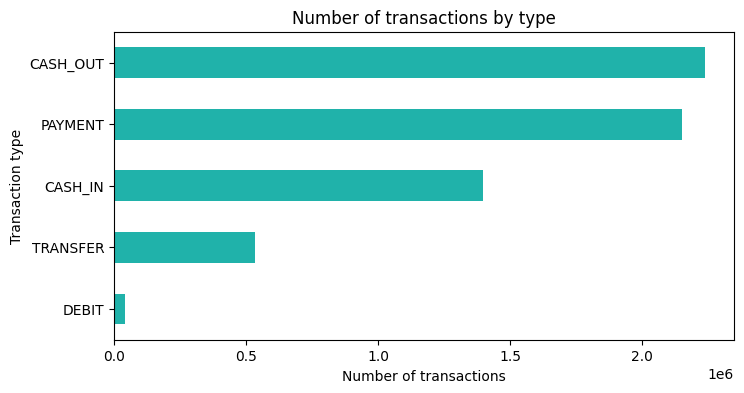

In [77]:
type_stats["transactions"].sort_values().plot(
    kind="barh",
    figsize=(8, 4),
    title="Number of transactions by type"
)

plt.xlabel("Number of transactions")
plt.ylabel("Transaction type")
plt.show()

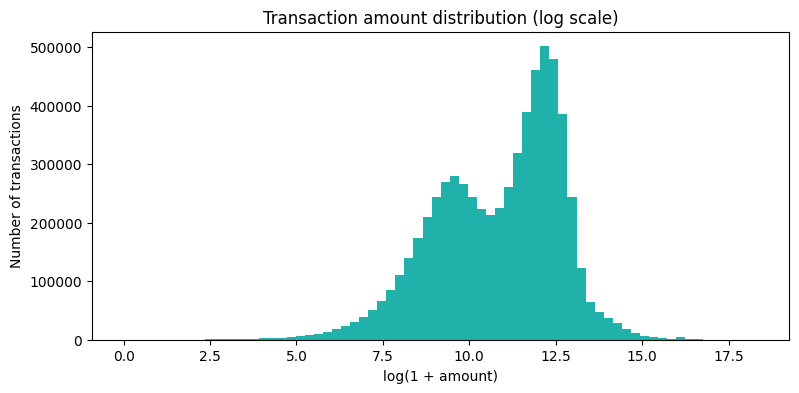

In [78]:
fig = plt.figure(figsize=(9, 4))

plt.hist(
    np.log1p(df["amount"]),
    bins=70,
)

plt.title("Transaction amount distribution (log scale)")
plt.xlabel("log(1 + amount)")
plt.ylabel("Number of transactions")

plt.show()

In [79]:
display(
    pd.crosstab(
        df["isFraud"],
        df["isFlaggedFraud"],
        margins=True,
    )
)

isFlaggedFraud,0,1,All
isFraud,,,
0,6354407,0,6354407
1,8197,16,8213
All,6362604,16,6362620


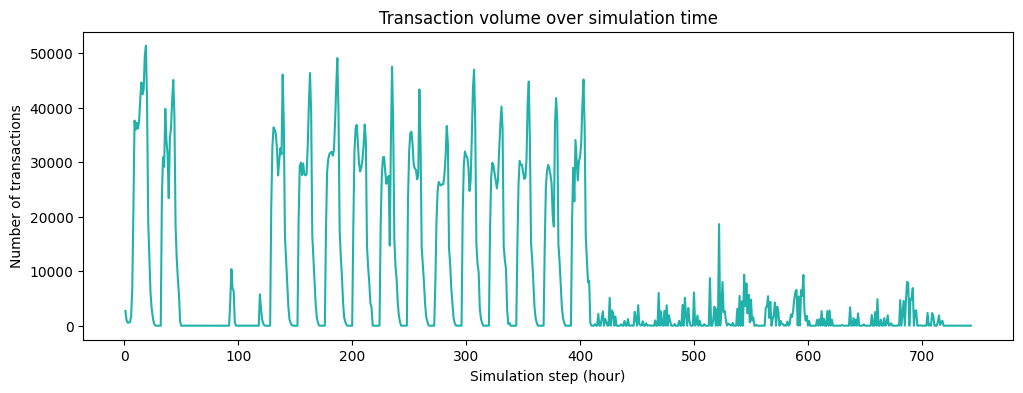

count      743.000000
mean      8563.418573
std      13388.693217
min          2.000000
25%         12.000000
50%        529.000000
75%      12317.000000
max      51352.000000
dtype: float64

In [80]:
transactions_per_step = df.groupby("step").size()

plt.figure(figsize=(12, 4))
plt.plot(
    transactions_per_step.index,
    transactions_per_step.values
)

plt.title("Transaction volume over simulation time")
plt.xlabel("Simulation step (hour)")
plt.ylabel("Number of transactions")
plt.show()

display(transactions_per_step.describe())

In [89]:
print("Unique senders:", df["nameOrig"].nunique())
print("Unique recipients:", df["nameDest"].nunique())

print("Accounts appearing as both sender and recipient:", len(set(df["nameOrig"]) & set(df["nameDest"])))

Unique senders: 6353307
Unique recipients: 2722362
Accounts appearing as both sender and recipient: 1769


In [82]:
df["nameOrig"].value_counts()

nameOrig
C1902386530    3
C363736674     3
C545315117     3
C724452879     3
C1784010646    3
              ..
C98968405      1
C720209255     1
C1567523029    1
C644777639     1
C1280323807    1
Name: count, Length: 6353307, dtype: int64

In [90]:
SPLIT_STEP = 500

historical_df = df[df["step"] <= SPLIT_STEP].copy()
stream_df = df[df["step"] > SPLIT_STEP].copy()

print("Historical transactions:", len(historical_df))
print("Streaming transactions:", len(stream_df))

print("Historical (%):", round(len(historical_df) / len(df) * 100, 2))
print("Streaming (%):", round(len(stream_df) / len(df) * 100, 2))

Historical transactions: 6061807
Streaming transactions: 300813
Historical (%): 95.27
Streaming (%): 4.73


In [91]:
historical_users = set(historical_df["nameOrig"])
stream_users = set(stream_df["nameOrig"])

common_users = historical_users & stream_users
new_users = stream_users - historical_users

print("Historical users:", len(historical_users))
print("Streaming users:", len(stream_users))
print("Common users:", len(common_users))
print("New users:", len(new_users))

print("Returning users (%):", round(len(common_users) / len(stream_users) * 100, 2))

print("New users (%):", round(len(new_users) / len(stream_users) * 100, 2))

Historical users: 6053327
Streaming users: 300794
Common users: 814
New users: 299980
Returning users (%): 0.27
New users (%): 99.73


In [92]:
stream_df["is_new_user"] = ~stream_df["nameOrig"].isin(historical_users)

stream_df["is_new_user"].value_counts(normalize=True) * 100

is_new_user
True     99.729068
False     0.270932
Name: proportion, dtype: float64

In [93]:
recipient_counts = df["nameDest"].value_counts()

display(recipient_counts.describe(
    percentiles=[0.5, 0.9, 0.99, 0.999]
))

print("Recipients with more than one transaction:", (recipient_counts > 1).sum())
print("Maximum transactions per recipient:", recipient_counts.max())

count    2.722362e+06
mean     2.337169e+00
std      4.549264e+00
min      1.000000e+00
50%      1.000000e+00
90%      5.000000e+00
99%      2.500000e+01
99.9%    4.400000e+01
max      1.130000e+02
Name: count, dtype: float64

Recipients with more than one transaction: 459658
Maximum transactions per recipient: 113


In [94]:
historical_accounts = (
    set(historical_df["nameOrig"])
    | set(historical_df["nameDest"])
)

stream_senders = set(stream_df["nameOrig"])

known_senders = stream_senders & historical_accounts

print("Streaming senders:", len(stream_senders))
print("Known in history (any role):", len(known_senders))
print("Known in history (%):", round(len(known_senders) / len(stream_senders) * 100, 2))

Streaming senders: 300794
Known in history (any role): 883
Known in history (%): 0.29


In [95]:
recipient_stats = df.assign(
    recipient_type=df["nameDest"].str[0]
).groupby("recipient_type").agg(
    transactions=("nameDest", "size"),
    unique_recipients=("nameDest", "nunique")
)

recipient_stats["avg_transactions_per_recipient"] = (
    recipient_stats["transactions"] /
    recipient_stats["unique_recipients"]
)

display(recipient_stats)

,transactions,unique_recipients,avg_transactions_per_recipient
recipient_type,,,
C,4211125,571961,7.362609
M,2151495,2150401,1.000509
